rumz
# Notebook for processing ice through code in icespec folder
### Dec 24

This notebook processes hyperspectral images of ice

In this cell libraries and modules are imported for use

In [1]:
import warnings
import sys
import os

# Add the processing folder to the Python path
processing_path = os.path.abspath(os.path.join('..', 'processing'))
if processing_path not in sys.path:
    sys.path.append(processing_path)

#Importing Python Libraries and Packages

import pandas as pd
import numpy as np

import set_icespec_path as tool
icespec_code_path=tool.add_icespec_code_dir()
tool.add_icespec_code_dir()
from icespec import icespec_process1_module as processice
from icespec import get_size_module as getSize

In [2]:
csv_path = os.path.abspath(os.path.join('..', 'processing', 'Cores.csv'))
DataFrame = pd.read_csv(csv_path) #reading in file with core data
#print(DataFrame)

### Users should fill in variables with desired core info
Use Cores.csv Spreadsheet for ID and section names

Debug variable prints more information during processing

In [3]:
datasetPath = '/nfs/hsi/ICF_Collected/Jan2024/Denali/' #path to data folder on computer or server

CoreID = "DEN13A - 228" #insert core name inside quotation marks
# WDC will cause errors

Debug = False

In [4]:
CoreData = DataFrame.loc[DataFrame['Core'] == CoreID] # Accessing data for Core
Row = DataFrame[DataFrame['Core'] == CoreID].index[0] # Grabbing row index for future access
print(CoreData)
scanNum = DataFrame._get_value(Row, 'Scans') # getting Core scan number
print(CoreID, " has ", scanNum, " scans.")
corePath = DataFrame._get_value(Row, 'FilePath') # getting Core file path

            Core  Scans  TopPx  BottomPX  LeftPX  RightPx  Standard1 TopPx  \
14  DEN13A - 228      8   1288      4730       3      510                3   

    Standard1 BottomPx  Standard2 TopPx  Standard2 BottomPx  Standard3 TopPx  \
14                 228              248                 580              587   

    Standard3 BottomPx  Standards LeftPx  Standards RightPx  \
14                 915                 3                860   

                                             FilePath Notes  
14  /nfs/hsi/ICF_Collected/Jan2024/Denali/ICF_DEN1...   NaN  
DEN13A - 228  has  8  scans.


This cell will print out the paths used to capture data from the server

In [5]:
datasetPaths = processice.getDenaliPath(scanNum, corePath) #file traverse module will take csv data to complete file paths for each scan
print(datasetPaths)
dataPath = datasetPaths[1] #use this to only run one dataset

['/nfs/hsi/ICF_Collected/Jan2024/Denali/ICF_DEN13A-228_0001', '/nfs/hsi/ICF_Collected/Jan2024/Denali/ICF_DEN13A-228_0002', '/nfs/hsi/ICF_Collected/Jan2024/Denali/ICF_DEN13A-228_0003', '/nfs/hsi/ICF_Collected/Jan2024/Denali/ICF_DEN13A-228_0004', '/nfs/hsi/ICF_Collected/Jan2024/Denali/ICF_DEN13A-228_0005', '/nfs/hsi/ICF_Collected/Jan2024/Denali/ICF_DEN13A-228_0006', '/nfs/hsi/ICF_Collected/Jan2024/Denali/ICF_DEN13A-228_0007', '/nfs/hsi/ICF_Collected/Jan2024/Denali/ICF_DEN13A-228_0008']


This cell contains the code used to retrieve the hyperspectral image to be processed

In [ ]:
data_nparr, w_ref, d_ref, fwhm = processice.getEnviData(dataPath, Debug)

This cell calls the trim functionality to get rid of unnecessary data

In [ ]:
dataSize, stdSize = getSize.retrieveData(DataFrame, Row)
trimmedData = processice.trim(data_nparr, w_ref, d_ref, dataSize, stdSize, Debug=True) #return arr of 3 trimmed

The cell below calls 2 funtions
- The first will correct any lighting inaccuracies
- The second trims spectral bands with unhelpful data

In [ ]:
correctedData = processice.reflectance(trimmedData, Debug)
filtered_img = processice.remove_bands(correctedData, trimmedData[1])

This cell shows a preview of the image as it is trimmed, corrected, and filtered

In [ ]:
previewed_img = processice.previewImg(filtered_img, "[Title Here]")

This cell processes and fills in bubbles in the ice image

In [ ]:
inpainted_img = processice.bubbles(filtered_img,  fwhm)

This cell calls a funtion flatten the 3d image aray into 2 dimensions

In [ ]:
flattened_img = processice.flatten_data(inpainted_img)

This cell reforms the image into a 3d array showing Principle Components
- changing the PC number may yield different results

In [ ]:
rematrix_img = processice.resize_matrix(flattened_img, trimmedData, pc_num = 5) #pc_num can be changed

This cell calls a function to enchance the image

In [ ]:
eq_img = processice.equalize(rematrix_img)

### Use this cell to run all datasets

/home/rumz/anaconda3/envs/HSenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)


Trimmed shapes: (3442, 507, 224),W_ref: (116, 507, 224),D_ref:(100, 507, 224)


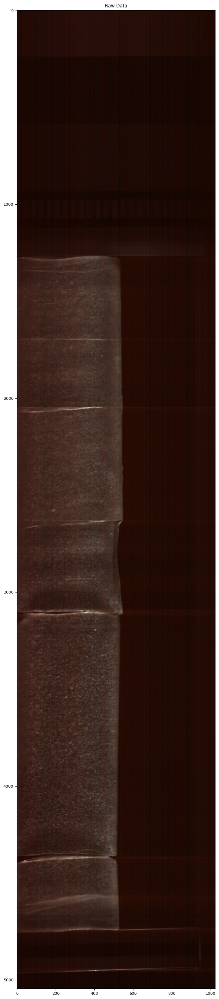

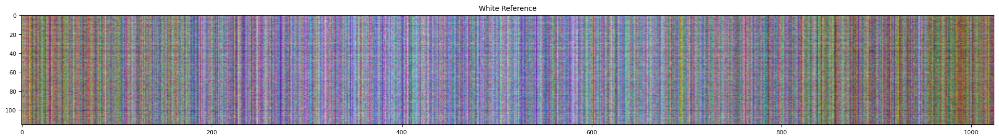

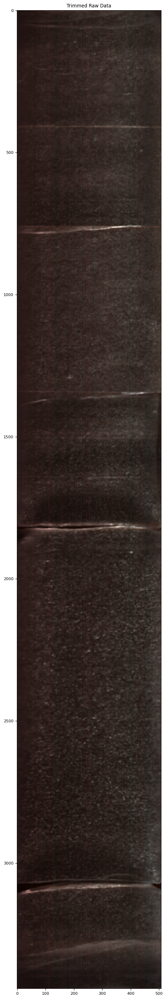

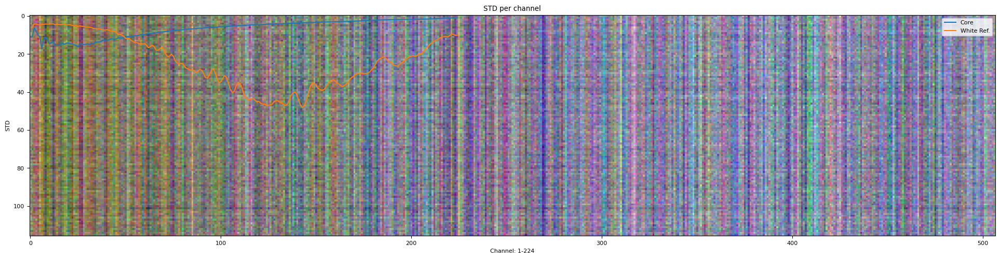

/home/rumz/src/stat/icespec/filter_bands_module.py:63: RuntimeWarning: invalid value encountered in sqrt
  SNR = np.sqrt(np.array(data_var)**2 / np.array(wht_var)**2 - 1)


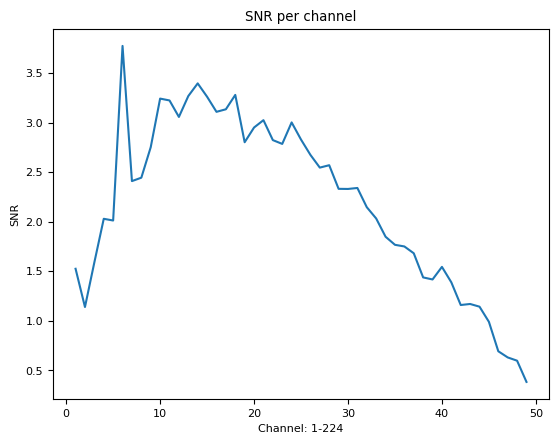

Bad Bands:  [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223]
Shape Before:  (3442, 507, 224)
Shape After:  (3442, 507, 163)
Flattened shape:  (1745094, 163)
Valid Data shape:  (1745094, 163)
pca shape:  (1745094, 5)
Rematrix shape:  (3442, 507, 5)


/home/rumz/anaconda3/envs/HSenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)
/home/rumz/src/stat/icespec/icespec_process1_module.py:154: UserWarning: Possible precision loss converting image of type float64 to uint8 as required by rank filters. Convert manually using skimage.util.img_as_ubyte to silence this warning.
  equalized = equalizer.analyze_data(image)


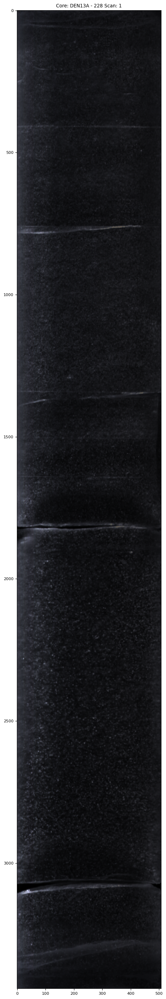

<Figure size 2400x3600 with 0 Axes>

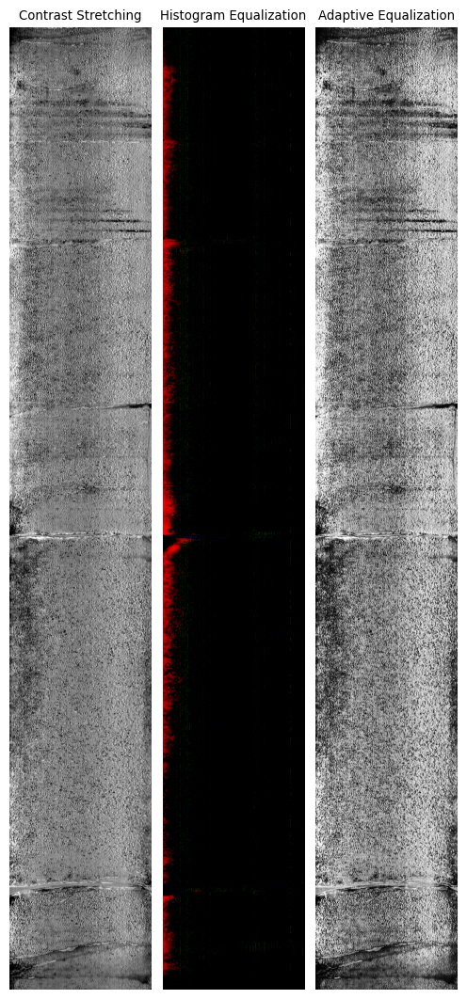

Trimmed shapes: (3442, 507, 224),W_ref: (116, 507, 224),D_ref:(100, 507, 224)


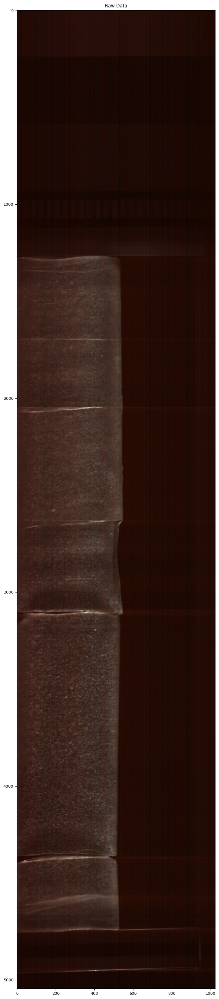

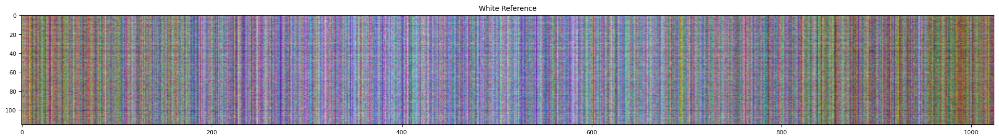

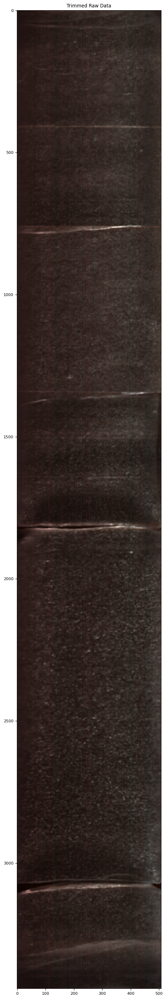

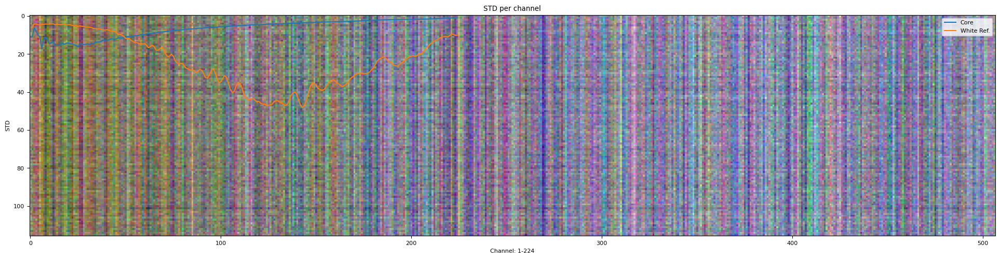

/home/rumz/src/stat/icespec/filter_bands_module.py:63: RuntimeWarning: invalid value encountered in sqrt
  SNR = np.sqrt(np.array(data_var)**2 / np.array(wht_var)**2 - 1)


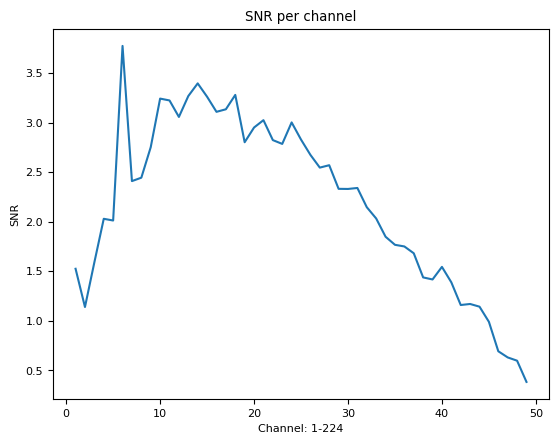

Bad Bands:  [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223]
Shape Before:  (3442, 507, 224)
Shape After:  (3442, 507, 163)
Flattened shape:  (1745094, 163)
Valid Data shape:  (1745094, 163)
pca shape:  (1745094, 5)
Rematrix shape:  (3442, 507, 5)


/home/rumz/anaconda3/envs/HSenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)
/home/rumz/src/stat/icespec/icespec_process1_module.py:154: UserWarning: Possible precision loss converting image of type float64 to uint8 as required by rank filters. Convert manually using skimage.util.img_as_ubyte to silence this warning.
  equalized = equalizer.analyze_data(image)


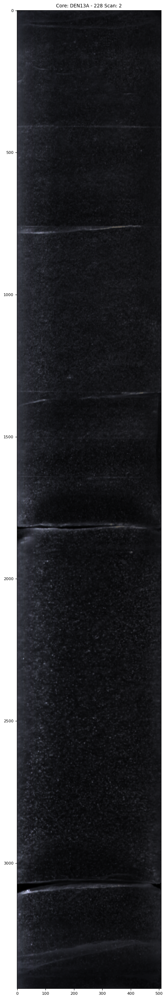

<Figure size 2400x3600 with 0 Axes>

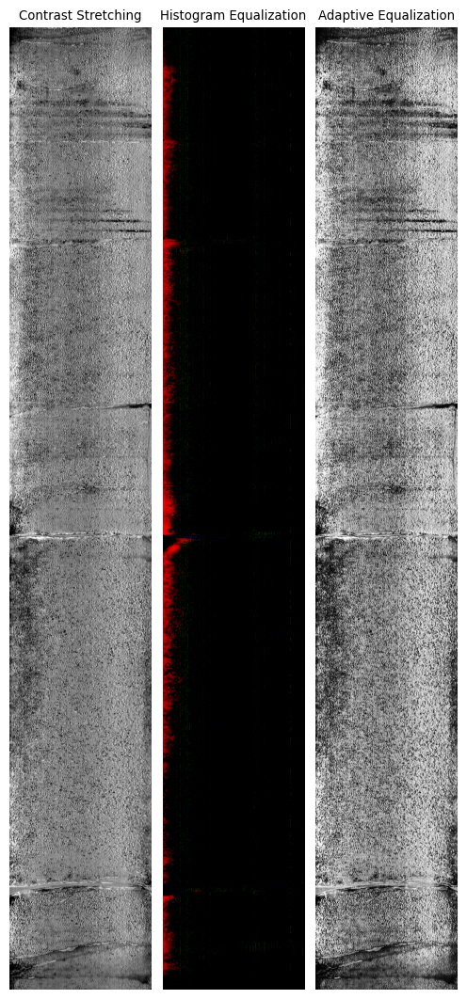

Trimmed shapes: (3442, 507, 224),W_ref: (116, 507, 224),D_ref:(100, 507, 224)


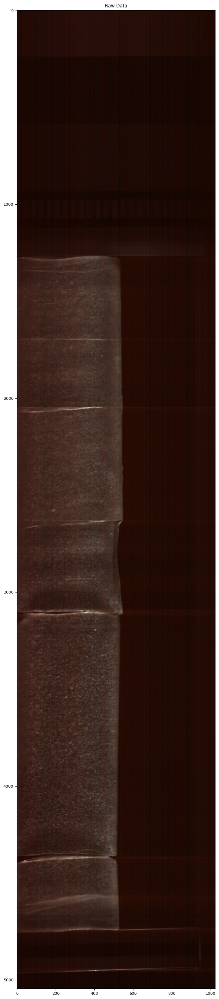

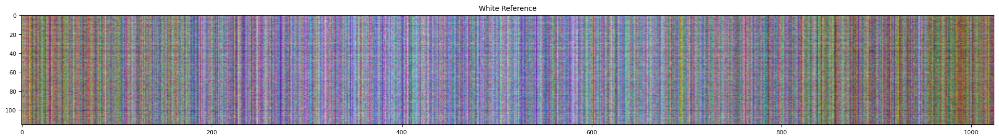

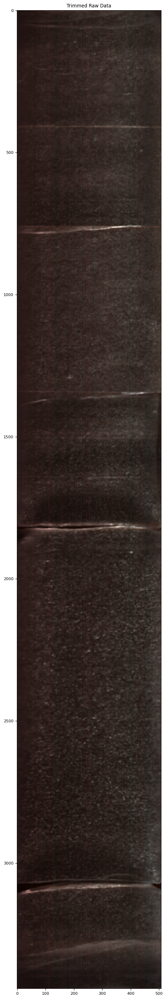

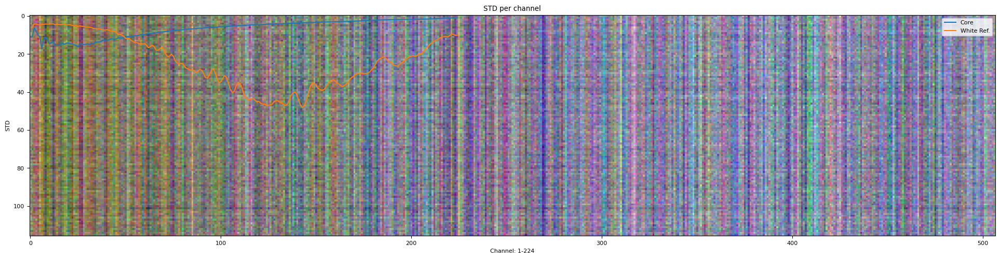

/home/rumz/src/stat/icespec/filter_bands_module.py:63: RuntimeWarning: invalid value encountered in sqrt
  SNR = np.sqrt(np.array(data_var)**2 / np.array(wht_var)**2 - 1)


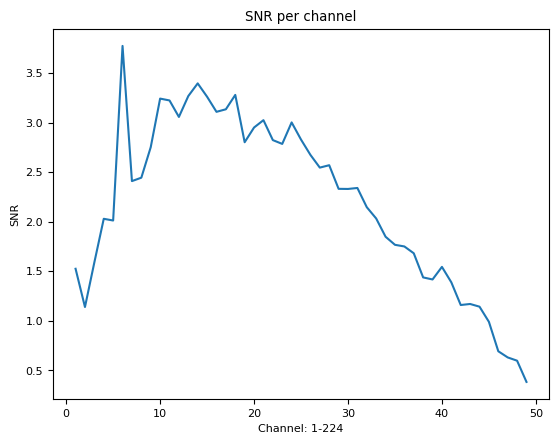

Bad Bands:  [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223]
Shape Before:  (3442, 507, 224)
Shape After:  (3442, 507, 163)
Flattened shape:  (1745094, 163)
Valid Data shape:  (1745094, 163)
pca shape:  (1745094, 5)
Rematrix shape:  (3442, 507, 5)


/home/rumz/anaconda3/envs/HSenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)
/home/rumz/src/stat/icespec/icespec_process1_module.py:154: UserWarning: Possible precision loss converting image of type float64 to uint8 as required by rank filters. Convert manually using skimage.util.img_as_ubyte to silence this warning.
  equalized = equalizer.analyze_data(image)


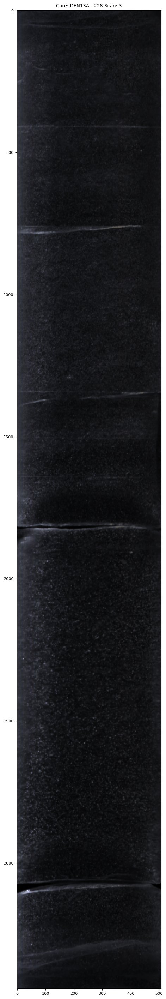

<Figure size 2400x3600 with 0 Axes>

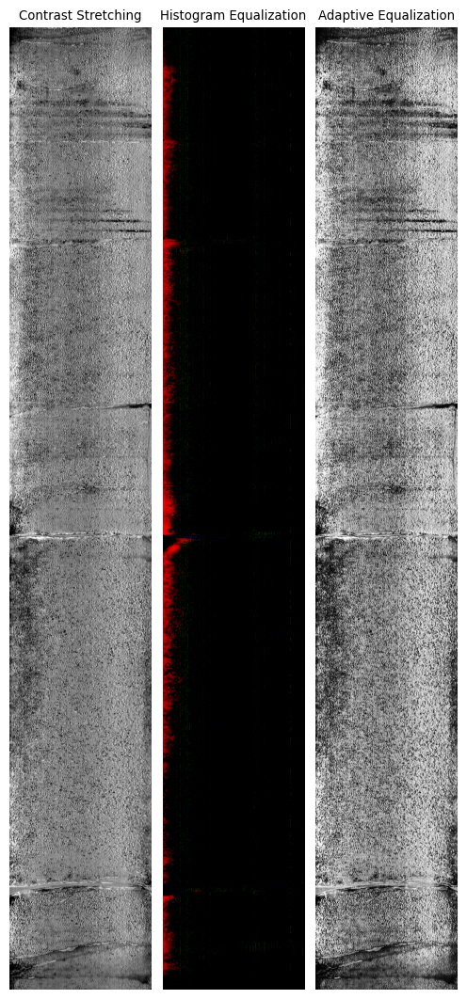

Trimmed shapes: (3442, 507, 224),W_ref: (116, 507, 224),D_ref:(100, 507, 224)


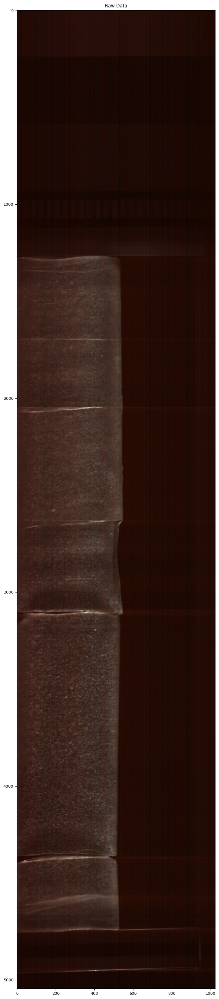

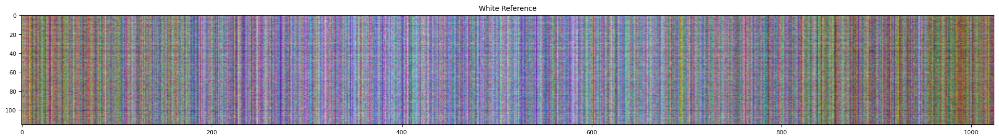

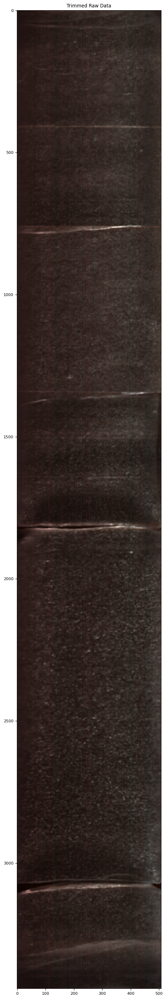

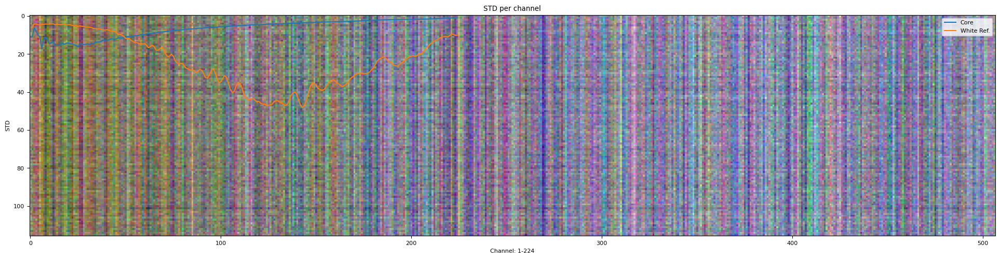

/home/rumz/src/stat/icespec/filter_bands_module.py:63: RuntimeWarning: invalid value encountered in sqrt
  SNR = np.sqrt(np.array(data_var)**2 / np.array(wht_var)**2 - 1)


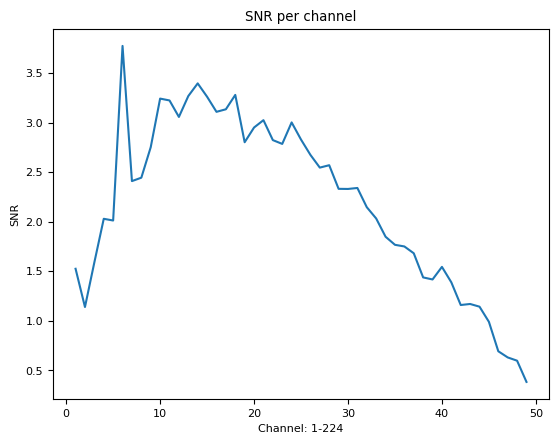

Bad Bands:  [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223]
Shape Before:  (3442, 507, 224)
Shape After:  (3442, 507, 163)
Flattened shape:  (1745094, 163)
Valid Data shape:  (1745094, 163)
pca shape:  (1745094, 5)
Rematrix shape:  (3442, 507, 5)


/home/rumz/anaconda3/envs/HSenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)
/home/rumz/src/stat/icespec/icespec_process1_module.py:154: UserWarning: Possible precision loss converting image of type float64 to uint8 as required by rank filters. Convert manually using skimage.util.img_as_ubyte to silence this warning.
  equalized = equalizer.analyze_data(image)


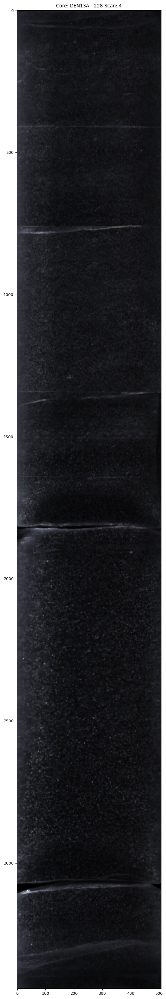

<Figure size 2400x3600 with 0 Axes>

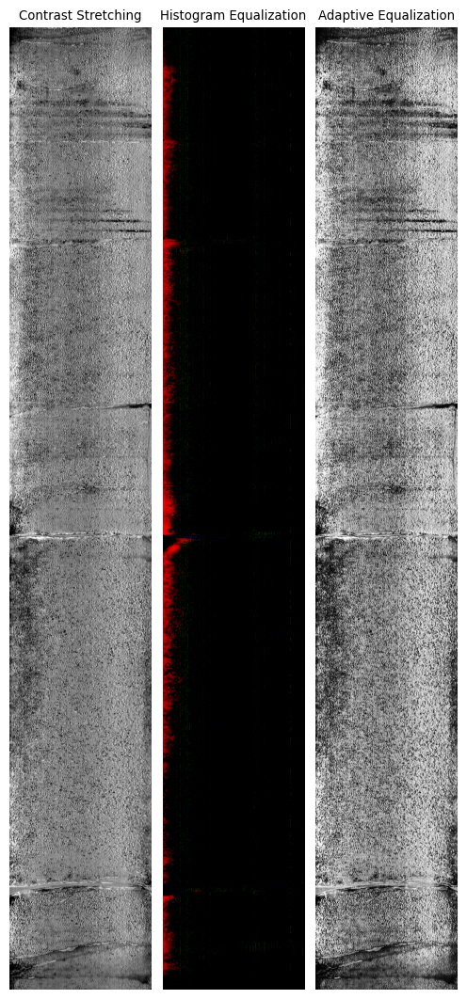

Trimmed shapes: (3442, 507, 224),W_ref: (116, 507, 224),D_ref:(100, 507, 224)


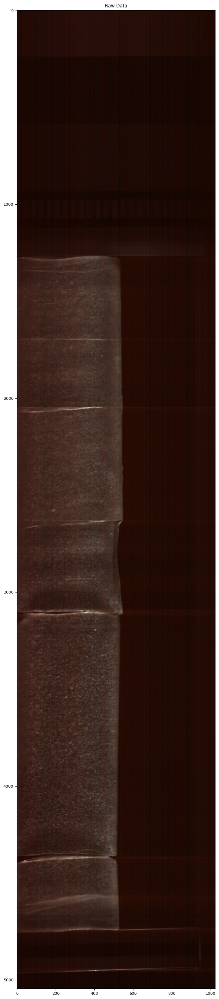

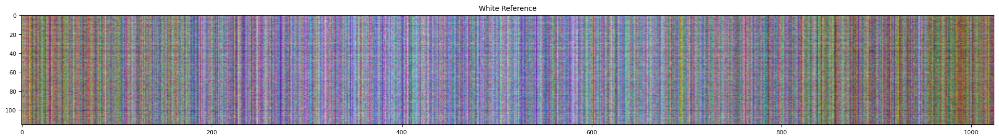

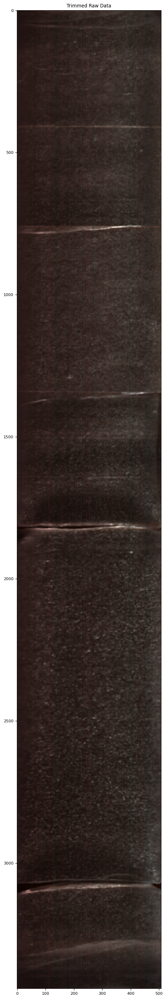

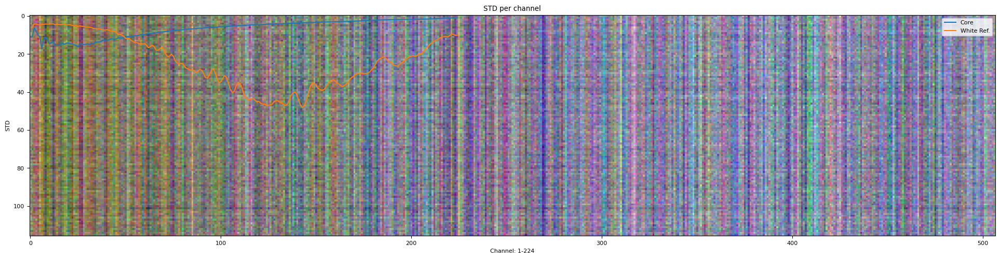

/home/rumz/src/stat/icespec/filter_bands_module.py:63: RuntimeWarning: invalid value encountered in sqrt
  SNR = np.sqrt(np.array(data_var)**2 / np.array(wht_var)**2 - 1)


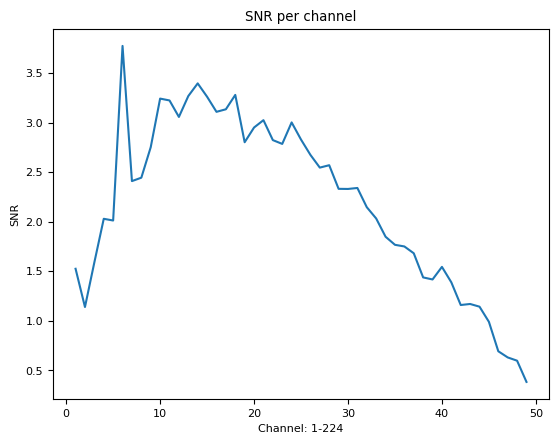

Bad Bands:  [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223]
Shape Before:  (3442, 507, 224)
Shape After:  (3442, 507, 163)
Flattened shape:  (1745094, 163)
Valid Data shape:  (1745094, 163)
pca shape:  (1745094, 5)
Rematrix shape:  (3442, 507, 5)


/home/rumz/anaconda3/envs/HSenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)
/home/rumz/src/stat/icespec/icespec_process1_module.py:154: UserWarning: Possible precision loss converting image of type float64 to uint8 as required by rank filters. Convert manually using skimage.util.img_as_ubyte to silence this warning.
  equalized = equalizer.analyze_data(image)


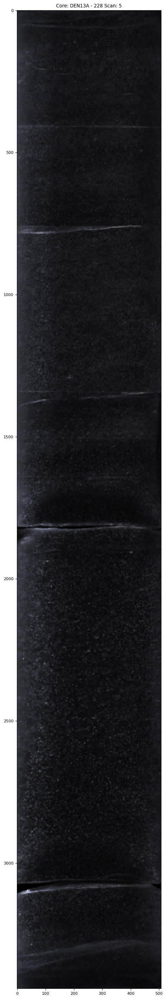

<Figure size 2400x3600 with 0 Axes>

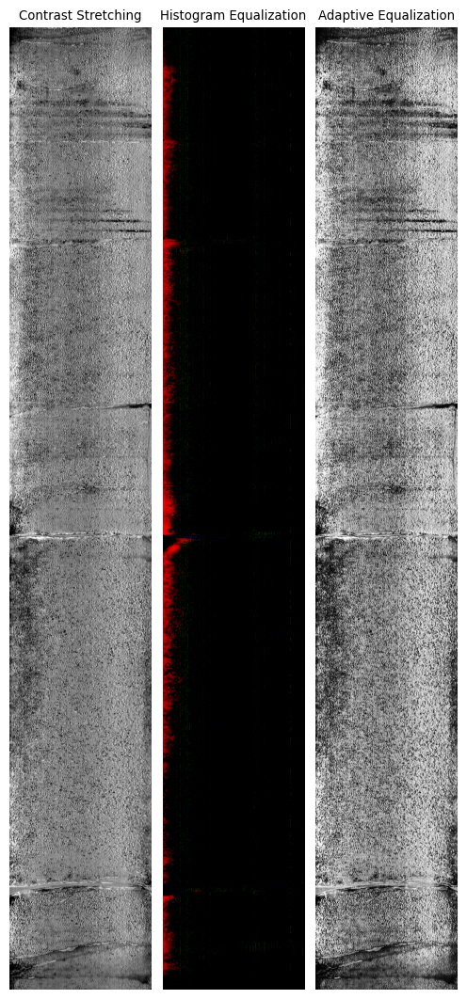

Trimmed shapes: (3442, 507, 224),W_ref: (116, 507, 224),D_ref:(100, 507, 224)


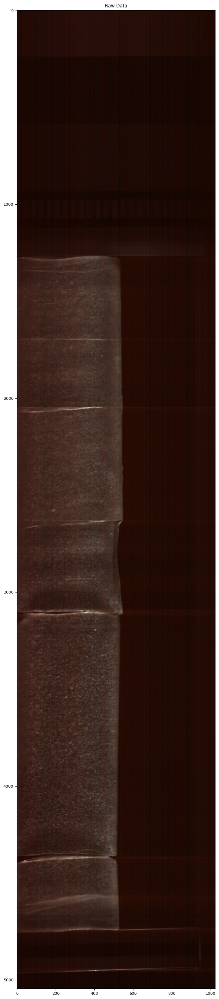

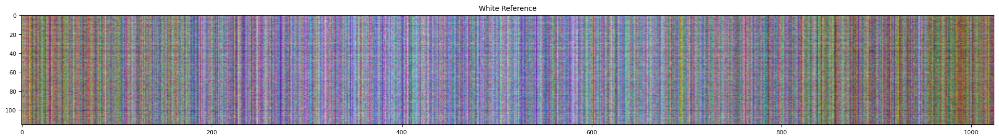

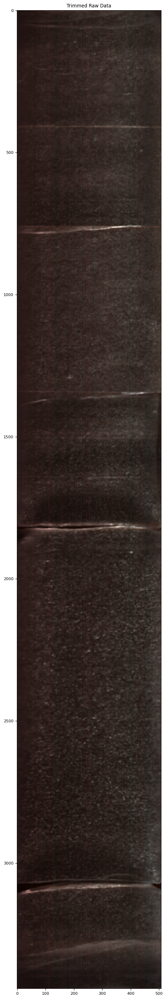

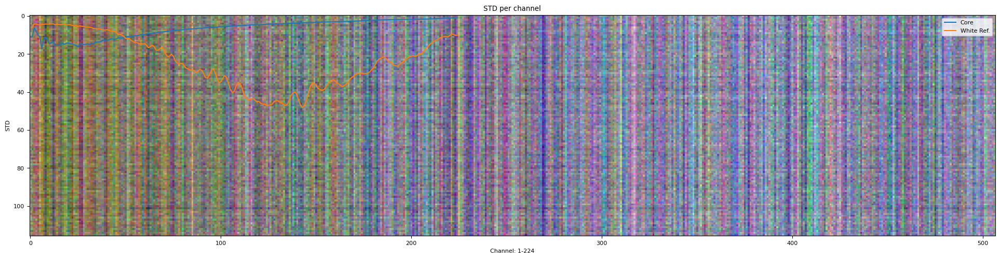

/home/rumz/src/stat/icespec/filter_bands_module.py:63: RuntimeWarning: invalid value encountered in sqrt
  SNR = np.sqrt(np.array(data_var)**2 / np.array(wht_var)**2 - 1)


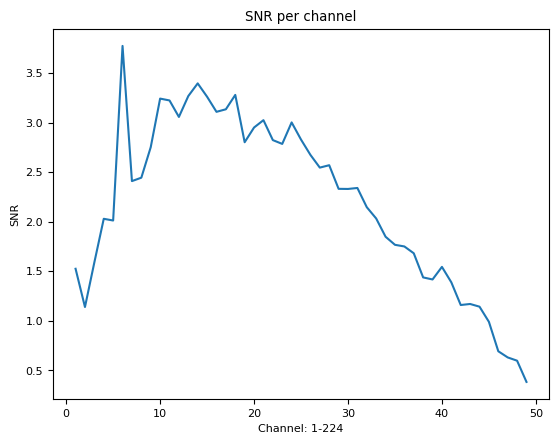

Bad Bands:  [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223]
Shape Before:  (3442, 507, 224)
Shape After:  (3442, 507, 163)
Flattened shape:  (1745094, 163)
Valid Data shape:  (1745094, 163)
pca shape:  (1745094, 5)
Rematrix shape:  (3442, 507, 5)


/home/rumz/anaconda3/envs/HSenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)
/home/rumz/src/stat/icespec/icespec_process1_module.py:154: UserWarning: Possible precision loss converting image of type float64 to uint8 as required by rank filters. Convert manually using skimage.util.img_as_ubyte to silence this warning.
  equalized = equalizer.analyze_data(image)


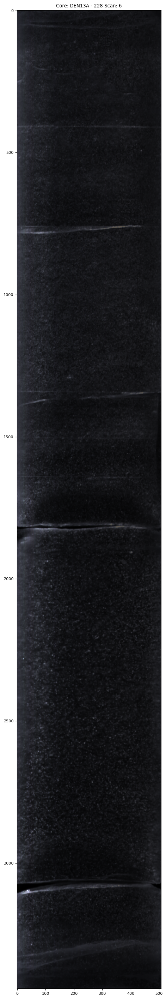

<Figure size 2400x3600 with 0 Axes>

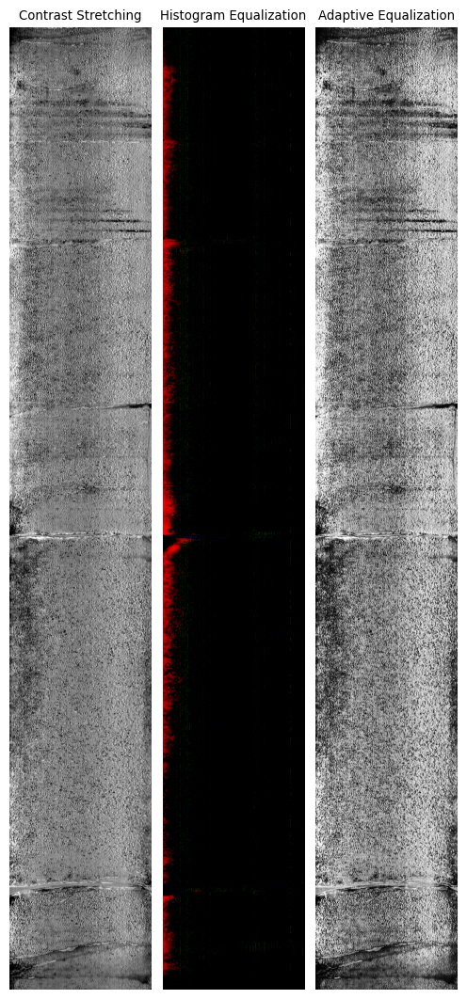

Trimmed shapes: (3442, 507, 224),W_ref: (116, 507, 224),D_ref:(100, 507, 224)


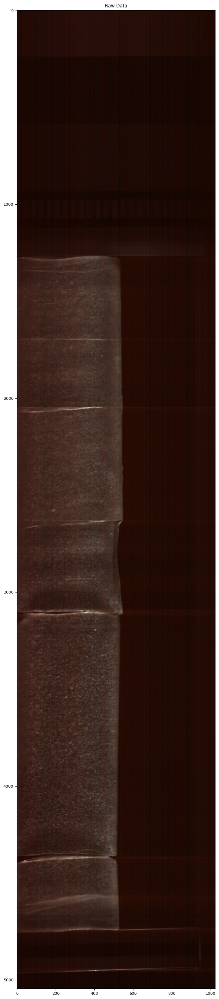

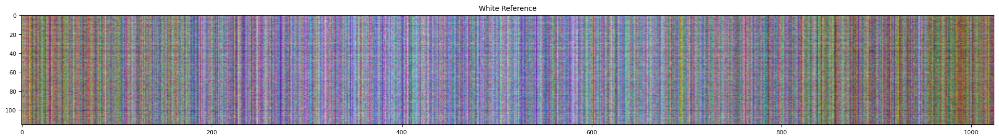

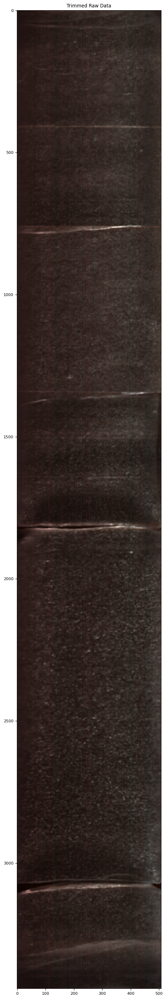

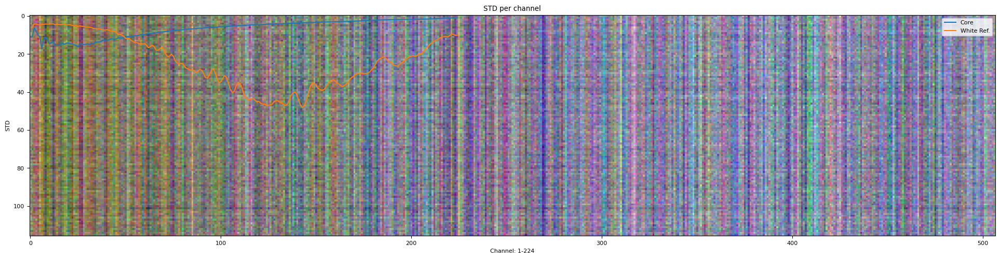

/home/rumz/src/stat/icespec/filter_bands_module.py:63: RuntimeWarning: invalid value encountered in sqrt
  SNR = np.sqrt(np.array(data_var)**2 / np.array(wht_var)**2 - 1)


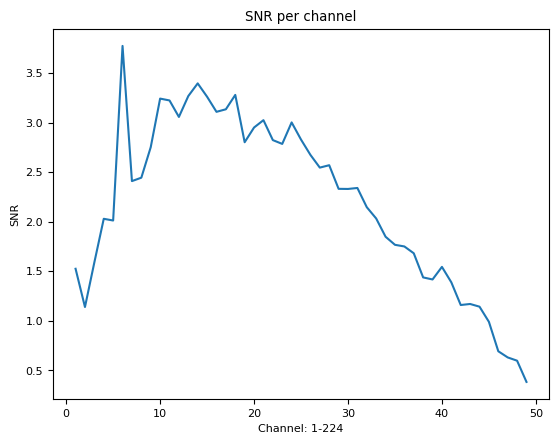

Bad Bands:  [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223]
Shape Before:  (3442, 507, 224)
Shape After:  (3442, 507, 163)
Flattened shape:  (1745094, 163)
Valid Data shape:  (1745094, 163)
pca shape:  (1745094, 5)
Rematrix shape:  (3442, 507, 5)


/home/rumz/anaconda3/envs/HSenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)
/home/rumz/src/stat/icespec/icespec_process1_module.py:154: UserWarning: Possible precision loss converting image of type float64 to uint8 as required by rank filters. Convert manually using skimage.util.img_as_ubyte to silence this warning.
  equalized = equalizer.analyze_data(image)


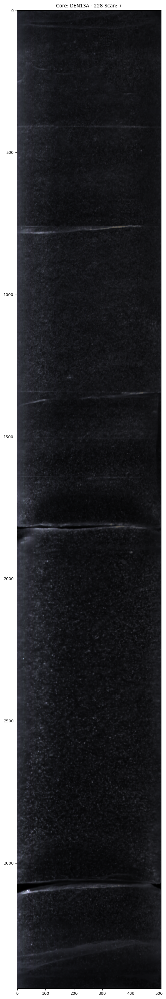

<Figure size 2400x3600 with 0 Axes>

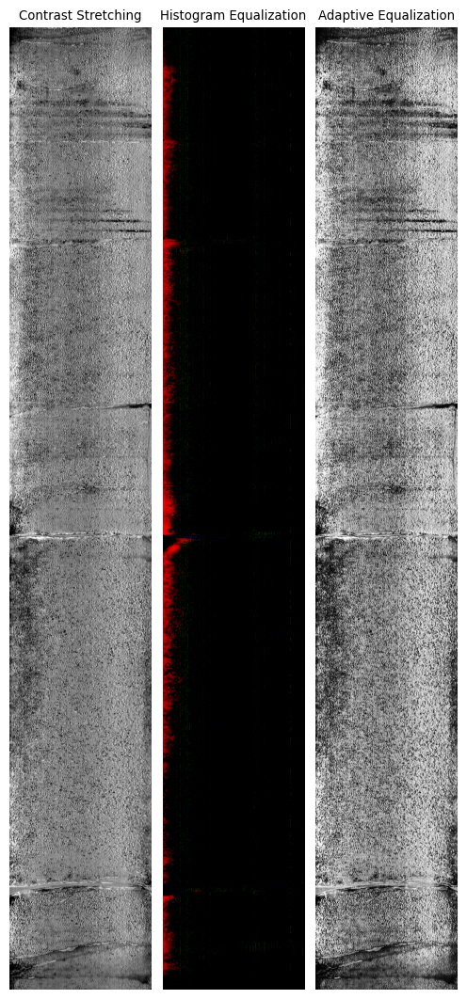

Trimmed shapes: (3442, 507, 224),W_ref: (116, 507, 224),D_ref:(100, 507, 224)


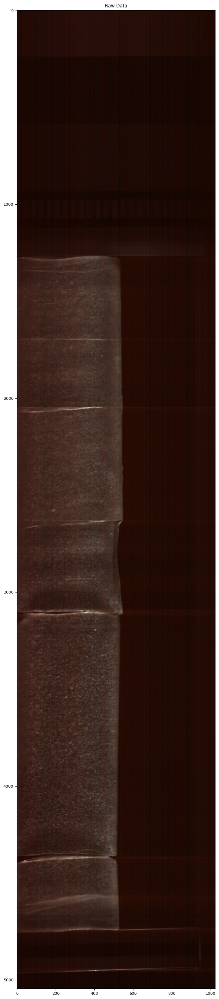

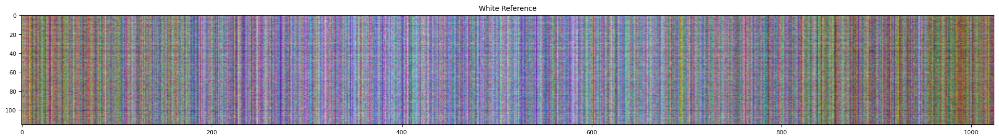

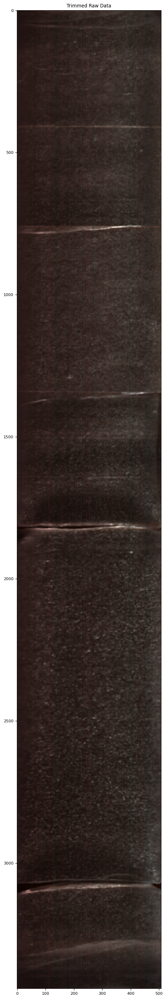

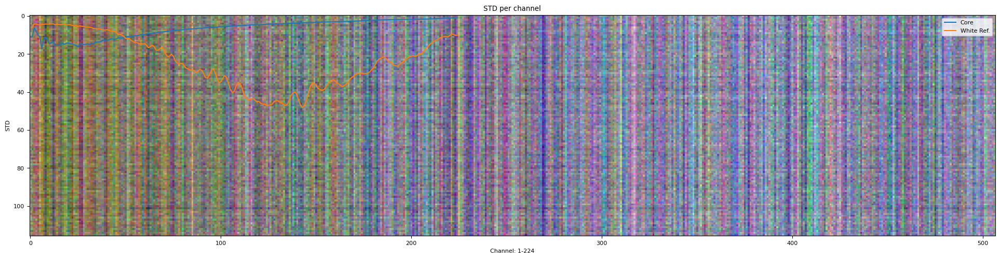

/home/rumz/src/stat/icespec/filter_bands_module.py:63: RuntimeWarning: invalid value encountered in sqrt
  SNR = np.sqrt(np.array(data_var)**2 / np.array(wht_var)**2 - 1)


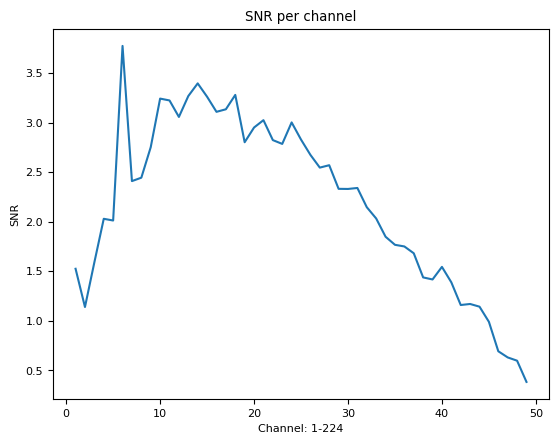

Bad Bands:  [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223]
Shape Before:  (3442, 507, 224)
Shape After:  (3442, 507, 163)
Flattened shape:  (1745094, 163)
Valid Data shape:  (1745094, 163)
pca shape:  (1745094, 5)
Rematrix shape:  (3442, 507, 5)


/home/rumz/anaconda3/envs/HSenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)
/home/rumz/src/stat/icespec/icespec_process1_module.py:154: UserWarning: Possible precision loss converting image of type float64 to uint8 as required by rank filters. Convert manually using skimage.util.img_as_ubyte to silence this warning.
  equalized = equalizer.analyze_data(image)


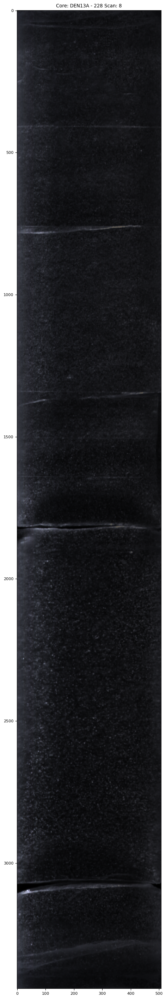

<Figure size 2400x3600 with 0 Axes>

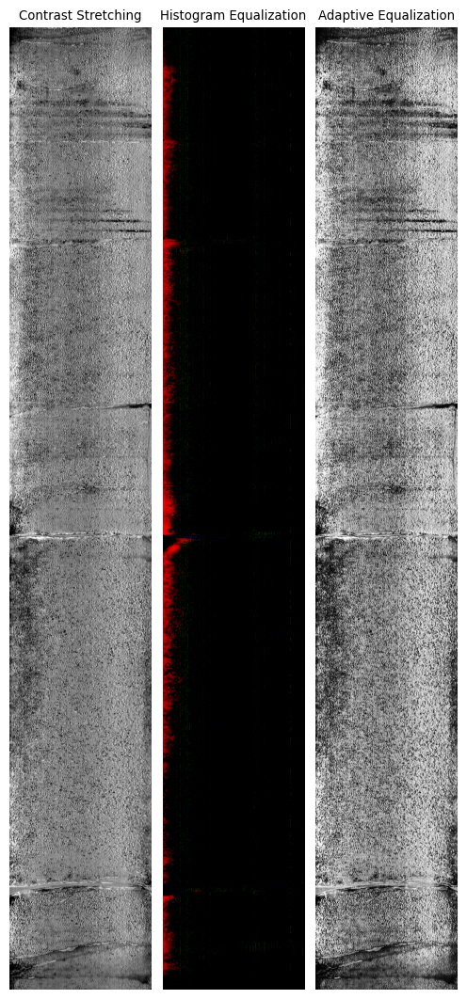

In [6]:
scanInt = 1

for data in datasetPaths:
    data_nparr, w_ref, d_ref, fwhm = processice.getEnviData(dataPath, Debug)
    dataSize, stdSize = getSize.retrieveData(DataFrame, Row)
    trimmedData = processice.trim(data_nparr, w_ref, d_ref, dataSize, stdSize, Debug=True) #return arr of 3 trimmed
    correctedData = processice.reflectance(trimmedData, Debug)
    filtered_img = processice.remove_bands(correctedData, trimmedData[1])
    previewed_img = processice.previewImg(filtered_img, f"Core: {CoreID} Scan: {scanInt}")
    inpainted_img = processice.bubbles(filtered_img,  fwhm)
    flattened_img = processice.flatten_data(inpainted_img)
    rematrix_img = processice.resize_matrix(flattened_img, trimmedData, pc_num = 5) #pc_num can be changed
    eq_img = processice.equalize(rematrix_img)
    scanInt += 1